In [ ]:
# Step 1. import library

import pandas as pd                                                       #tabular data
import numpy as np                                                        #numerical data
import matplotlib.pyplot as plt                                           #visulization

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler                          #data ko ek hi row me rakhna for understand
from sklearn.linear_model import LogisticRegression                       #for binary classification
from sklearn.pipeline import Pipeline                                     #for run the code in systmatic way
from sklearn.metrics import (accuracy_score,precision_score,
                             recall_score,f1_score,confusion_matrix,
                             classification_report)
                                                                          #for evaluation data
print("library import successfully")

library import successfully


In [ ]:
# Step 2. Load dataset file
# We use on_bad_lines='skip' to bypass rows with parsing issues, which are common in text-heavy datasets
df = pd.read_csv("/content/fake_job_postings.csv", on_bad_lines='skip')
print("dataset loaded successfully")

dataset loaded successfully


In [ ]:
#step 3 information
print("First Five rows :")
print(df.head())
print("Shape (rows,columns):",df.shape)
print("Column names:",df.columns)
print("Data types and non-null counts: ")
df.info()
print("Statistical summary: ")
print(df.describe())

First Five rows :
   job_id                                      title            location  \
0       1                           Marketing Intern    US, NY, New York   
1       2  Customer Service - Cloud Video Production      NZ, , Auckland   
2       3    Commissioning Machinery Assistant (CMA)       US, IA, Wever   
3       4          Account Executive - Washington DC  US, DC, Washington   
4       5                        Bill Review Manager  US, FL, Fort Worth   

  department salary_range                                    company_profile  \
0  Marketing          NaN  We're Food52, and we've created a groundbreaki...   
1    Success          NaN  90 Seconds, the worlds Cloud Video Production ...   
2        NaN          NaN  Valor Services provides Workforce Solutions th...   
3      Sales          NaN  Our passion for improving quality of life thro...   
4        NaN          NaN  SpotSource Solutions LLC is a Global Human Cap...   

                                         des

In [ ]:
#Step 4- Check Data Quality
print("Missing values: ")
print(df.isnull().sum())
print("Duplicate rows: ")
print(df.duplicated().sum())
print("Class distribution: ")
print(df["fraudulent"].value_counts())

Missing values: 
job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
dtype: int64
Duplicate rows: 
0
Class distribution: 
fraudulent
0    17014
1      866
Name: count, dtype: int64


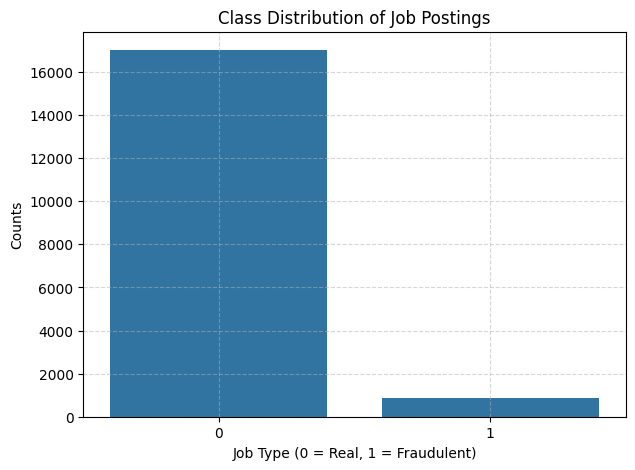

In [ ]:
# Step 5. Visualization - Real vs Fraudulent Job Distribution
import seaborn as sns
plt.figure(figsize=(7, 5))
sns.countplot(x='fraudulent', data=df)
plt.xlabel("Job Type (0 = Real, 1 = Fraudulent)")
plt.ylabel("Counts")
plt.title("Class Distribution of Job Postings")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
#Step 6 Separate Numerical Features and Target
# Target column has some nulls, so we drop those rows first
df_clean = df.dropna(subset=["fraudulent"])

# Selecting only numeric features for our simple Logistic Regression
numerical_cols = ["telecommuting", "has_company_logo", "has_questions","required_education","company_profile","department"]

# Standardizing data types to integer
for col in numerical_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce').fillna(0).astype(int)

x = df_clean[numerical_cols]
y = df_clean["fraudulent"].astype(int)

print("Features selected:", numerical_cols)
print(x.head())

Features selected: ['telecommuting', 'has_company_logo', 'has_questions', 'required_education', 'company_profile', 'department']
   telecommuting  has_company_logo  has_questions  required_education  \
0              0                 1              0                   0   
1              0                 1              0                   0   
2              0                 1              0                   0   
3              0                 1              0                   0   
4              0                 1              1                   0   

   company_profile  department  
0                0           0  
1                0           0  
2                0           0  
3                0           0  
4                0           0  


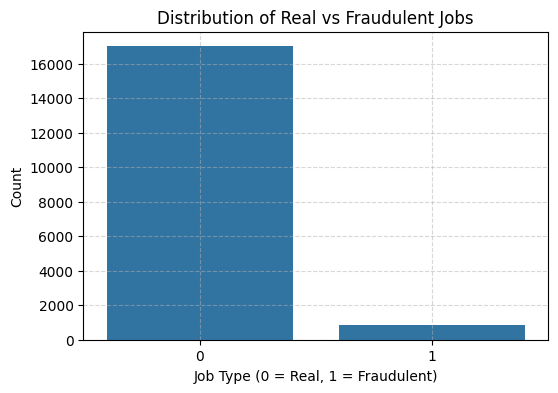

In [ ]:
# Step 7 Plotting - Class Distribution
import seaborn as sns
plt.figure(figsize=(6,4))
sns.countplot(x='fraudulent', data=df)
plt.xlabel("Job Type (0 = Real, 1 = Fraudulent)")
plt.ylabel("Count")
plt.title("Distribution of Real vs Fraudulent Jobs")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
#Step 7  Train-Test Split
x_train, x_test, y_train, y_test = train_test_split(x,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)
print("Train set shape:", x_train.shape)
print("Test set shape:", x_test.shape)

Train set shape: (14304, 3)
Test set shape: (3576, 3)


In [ ]:
#Step 8 Feature Scalling and Model Creation
model=Pipeline([ ("scaler",StandardScaler()), ("classifier",LogisticRegression()) ])
print("Pipeline created successfully.")

Pipeline created successfully.


In [ ]:
#Step 9  Train the Model
model.fit(x_train,y_train)
print("Model trained successfully.")

Model trained successfully.


In [ ]:
#Step 10 Predict the Test Data
y_pred = model.predict(x_test)
comparison = pd.DataFrame({ 'Actual': y_test.values, 'Predicted': y_pred })
print(comparison.head(10))
print("\nModel Accuracy:", accuracy_score(y_test, y_pred))

   Actual  Predicted
0       0          0
1       0          0
2       0          0
3       0          0
4       0          0
5       0          0
6       0          0
7       0          0
8       0          0
9       0          0

Model Accuracy: 0.9516219239373602
